<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: Academic Success Forecasting</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

### Question 1: Data Acquisition and Initial Inspection (3 Marks)

Load the student performance dataset into a Pandas DataFrame using the provided permanent URL. Display the shape of the DataFrame and its first three rows to verify successful ingestion.

**Hint:** Use the pandas library to read the CSV from `"https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/04_Apply/Students_Alcohol_Consumption/student-mat.csv"`. Examine the dimensions and preview the initial records.

**Expected Output:** A tuple showing the number of rows and columns, followed by a tabular display of the first three rows of the dataset.

In [ ]:
# Import pandas
import pandas as pd

# Load the data from the URL
url = "https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/04_Apply/Students_Alcohol_Consumption/student-mat.csv"
df = pd.read_csv(url)

# Show shape and first 3 rows
print(df.shape)
df.head(3)

(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10


### Question 2: Data Cleaning and Missing Value Justification (6 Marks)

Ensure the dataset's integrity by removing completely duplicated rows and addressing missing values (NaNs). Print the final shape of the DataFrame. Furthermore, provide a brief written justification explaining why dropping or imputing these records is statistically appropriate for this specific dataset.

**Hint:** Apply deduplication and missing value handling methods in pandas. Print your written answer using Python `print()` statements.

**Expected Output:** A printed tuple representing the dimensions of the cleaned dataset, accompanied by a printed text block explaining the data cleaning rationale.

In [ ]:
# Remove fully duplicated rows
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

# Final shape
print(df.shape)

# Justification
print("Justification:")
print("Duplicate rows carry no new information and would give some students extra weight, so they are dropped.")
print("Missing values are dropped (not imputed) because dropping loses very few rows in a ~400 student survey,")
print("and imputing could add artificial values that bias the mean and variance of the features.")
print("In this dataset no duplicates or NaNs were found, so the shape stays the same.")

(395, 33)
Justification:
Duplicate rows carry no new information and would give some students extra weight, so they are dropped.
Missing values are dropped (not imputed) because dropping loses very few rows in a ~400 student survey,
and imputing could add artificial values that bias the mean and variance of the features.
In this dataset no duplicates or NaNs were found, so the shape stays the same.


### Question 3: Target Variable Engineering (5 Marks)

The dataset tracks grades across three periods (G1, G2, G3). Create a single numerical column named `'Total_Grade'` representing the sum of these three features. To prevent data leakage during subsequent predictive modeling, permanently drop the original `'G1'`, `'G2'`, and `'G3'` columns.

**Hint:** Compute the sum of the specified period grades and assign it to the new column. Remove the original period grade columns from the DataFrame.

**Expected Output:** The DataFrame containing the new composite target column, with the three individual period columns successfully removed.

In [ ]:
# Create Total_Grade as the sum of G1, G2, G3
df['Total_Grade'] = df['G1'] + df['G2'] + df['G3']

# Drop the original grade columns to avoid data leakage
df = df.drop(columns=['G1', 'G2', 'G3'])

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,Total_Grade
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,no,4,3,4,1,1,3,6,17
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,no,5,3,3,1,1,3,4,16
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,no,4,3,2,2,3,3,10,25
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,3,2,2,1,1,5,2,44
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,no,4,3,2,1,2,5,4,26


### Question 4: Exploratory Data Analysis: Correlation Matrix (8 Marks)

Isolate the numerical columns in the dataset and compute their correlation matrix. Visualize this matrix using a heatmap. Identify the two features most strongly correlated (positively or negatively) with `'Total_Grade'` and explain the logical reason behind this relationship.

**Hint:** Use visualization libraries to plot the heatmap of the computed correlation matrix. Print your written answer using Python `print()` statements to interpret the top two correlated features.

**Expected Output:** A rendered heatmap visualization of numerical correlations and a printed analytical statement identifying and justifying the top correlated features.

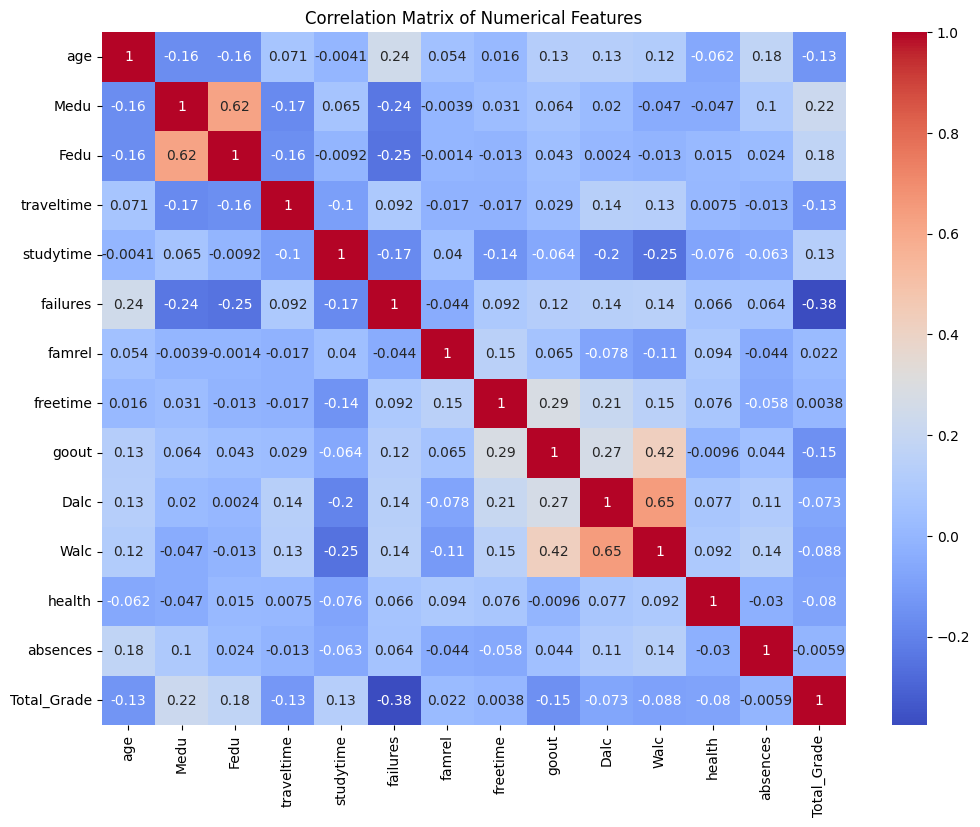

failures   -0.375759
Medu        0.224260
Name: Total_Grade, dtype: float64
The two strongest correlations with Total_Grade are 'failures' (about -0.38) and 'Medu' (about +0.22).
Students with more past class failures tend to have weaker foundations and lower grades (negative link).
Mother's education (Medu) is positive: more educated mothers usually give more academic support at home.


In [ ]:
# Import plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Keep only numerical columns and compute correlation matrix
num_df = df.select_dtypes(include='number')
corr = num_df.corr()

# Heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap='coolwarm', annot=True)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

# Top two features correlated with Total_Grade (by absolute value)
top2 = corr['Total_Grade'].drop('Total_Grade').abs().sort_values(ascending=False).head(2)
print(corr['Total_Grade'][top2.index])

# Written answer
print("The two strongest correlations with Total_Grade are 'failures' (about -0.38) and 'Medu' (about +0.22).")
print("Students with more past class failures tend to have weaker foundations and lower grades (negative link).")
print("Mother's education (Medu) is positive: more educated mothers usually give more academic support at home.")

### Question 5: Feature Separation and Categorical Encoding (6 Marks)

Separate the dataset into a feature matrix `X` and a target vector `y` (`'Total_Grade'`). Convert all categorical columns in `X` into a numerical format using one-hot encoding. Ensure that you drop the first category for each encoded feature to avoid multicollinearity.

**Hint:** Define `X` and `y` properly. Utilize pandas functions to generate dummy variables for the categorical columns in `X`, ensuring the redundant baseline categories are omitted.

**Expected Output:** A feature DataFrame composed entirely of numerical and boolean/integer indicators, alongside a separate target Series.

In [ ]:
# Separate features and target
X = df.drop(columns=['Total_Grade'])
y = df['Total_Grade']

# One-hot encode categorical columns, drop first category
X = pd.get_dummies(X, drop_first=True, dtype=int)

print(X.shape)
X.head()

(395, 39)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,...,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,0,1,0,1,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,1,0,0,1,1,1,1,1,1,1
4,16,3,3,1,2,0,4,3,2,1,...,0,0,0,1,1,0,1,1,0,0


### Question 6: Feature Scaling and DataFrame Reconstitution (7 Marks)

Standardize the encoded feature matrix `X` to have a mean of zero and a standard deviation of one. Convert the resulting multi-dimensional NumPy array back into a pandas DataFrame, explicitly retaining the original column names for interpretability in later stages.

**Hint:** Apply standard scaling using the appropriate preprocessing module. Reconstruct the DataFrame by passing the scaled array and referencing the columns from the pre-scaled `X`.

**Expected Output:** A scaled DataFrame with uniform variance across all features, preserving the exact column headers from the previous encoding step.

In [ ]:
# Import scaler
from sklearn.preprocessing import StandardScaler

# Standardize (mean 0, std 1)
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)

# Convert back to DataFrame with original column names
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns)

X_scaled.head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,1.023046,1.143856,1.360371,0.792251,-0.042286,-0.449944,0.062194,-0.236010,0.801479,-0.540699,...,0.668496,-0.296908,2.597133,-1.257656,-0.919671,-1.017881,0.507899,0.23094,-2.232677,-0.708450
1,0.238380,-1.600009,-1.399970,-0.643249,-0.042286,-0.449944,1.178860,-0.236010,-0.097908,-0.540699,...,-1.495896,-0.296908,-0.385040,0.795130,-0.919671,-1.017881,-1.968894,0.23094,0.447893,-0.708450
2,-1.330954,-1.600009,-1.399970,-0.643249,-0.042286,3.589323,0.062194,-0.236010,-0.997295,0.583385,...,0.668496,-0.296908,2.597133,-1.257656,1.087346,-1.017881,0.507899,0.23094,0.447893,-0.708450
3,-1.330954,1.143856,-0.479857,-0.643249,1.150779,-0.449944,-1.054472,-1.238419,-0.997295,-0.540699,...,0.668496,-0.296908,-0.385040,0.795130,1.087346,0.982433,0.507899,0.23094,0.447893,1.411533
4,-0.546287,0.229234,0.440257,-0.643249,-0.042286,-0.449944,0.062194,-0.236010,-0.997295,-0.540699,...,-1.495896,-0.296908,-0.385040,0.795130,1.087346,-1.017881,0.507899,0.23094,-2.232677,-0.708450


### Question 7: Dimensionality Reduction via PCA (7 Marks)

To facilitate unconstrained clustering, apply Principal Component Analysis (PCA) to the scaled feature DataFrame to condense the data into exactly two principal components. Store the output in a new Pandas DataFrame named `pca_df` with column headers `'PC1'` and `'PC2'`.

**Hint:** Initialize the decomposition algorithm to extract two components, fit and transform the scaled data, and structure the result as a DataFrame.

**Expected Output:** A new DataFrame containing exactly two numerical columns representing the primary orthogonal components of the scaled dataset.

In [ ]:
# Import PCA
from sklearn.decomposition import PCA

# Reduce to 2 components
pca = PCA(n_components=2)
pca_data = pca.fit_transform(X_scaled)

# Store in a DataFrame
pca_df = pd.DataFrame(pca_data, columns=['PC1', 'PC2'])

pca_df.head()

,PC1,PC2
0,1.464403,-0.039397
1,-0.930169,-2.253287
2,-1.469396,-0.584234
3,2.825809,-0.582528
4,0.364599,-1.913592


### Question 8: Unsupervised Learning: K-Means Elbow Method (8 Marks)

Determine the optimal number of learner segments by calculating the Within-Cluster Sum of Squares (WCSS/inertia) for cluster counts ranging from 1 to 10 inclusive. Plot the resulting inertia values to visually identify the elbow point.

**Hint:** Iterate through the specified range, fitting the clustering algorithm on `pca_df` at each step. Record the inertia metric and generate a line plot to evaluate the optimal K.

**Expected Output:** A line graph displaying progressively decreasing inertia values across the range of cluster counts, illustrating a distinct elbow.

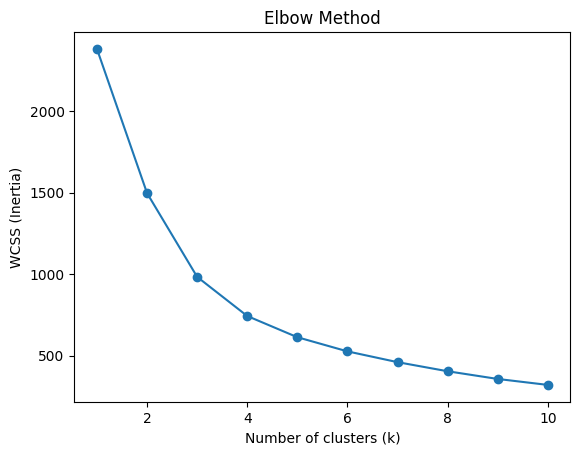

In [ ]:
# Import KMeans
from sklearn.cluster import KMeans

# Compute inertia (WCSS) for k = 1 to 10
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(pca_df)
    wcss.append(km.inertia_)

# Plot the elbow curve
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.title('Elbow Method')
plt.show()

### Question 9: Segment Profiling and Interpretation (8 Marks)

Assume the elbow method suggests 3 distinct clusters. Fit a K-Means model with 3 clusters on `pca_df` and append the labels to your original unscaled dataset `df`. Group the data by these clusters and compute the mean for `'Total_Grade'`, `'studytime'`, and `'absences'`. Analytically interpret what type of student profile each cluster represents.

**Hint:** Predict the cluster labels and assign them to a new column. Use groupby aggregation to compute the means. Print your written answer using Python `print()` statements to analyze the resulting table.

**Expected Output:** A summary table displaying three rows with average metrics, followed by a printed text block providing an academic profile analysis for each segment.

In [ ]:
# Fit KMeans with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(pca_df)

# Add cluster labels to the original (unscaled) df
df['Cluster'] = labels

# Mean of key columns per cluster
summary = df.groupby('Cluster')[['Total_Grade', 'studytime', 'absences']].mean()
print(summary)

# Written interpretation
print("Cluster 0: highest grades (~35.7) with average study time and few absences -> high achievers.")
print("Cluster 1: middle grades (~31.0) with the highest study time and fewest absences -> hardworking average students.")
print("Cluster 2: lowest grades (~27.3), lowest study time and most absences -> at-risk students.")

         Total_Grade  studytime  absences
Cluster                                  
0          35.676056   2.049296  5.584507
1          31.038462   2.241758  5.445055
2          27.323944   1.478873  6.633803
Cluster 0: highest grades (~35.7) with average study time and few absences -> high achievers.
Cluster 1: middle grades (~31.0) with the highest study time and fewest absences -> hardworking average students.
Cluster 2: lowest grades (~27.3), lowest study time and most absences -> at-risk students.


### Question 10: Train-Test Split & Baseline Regression (7 Marks)

Prepare the data for supervised modeling. Divide your scaled feature DataFrame and the target vector `y` into training (80%) and testing (20%) sets. Initialize and train a baseline Linear Regression model on the training data.

**Hint:** Use standard splitting functions with a set random state for reproducibility. Instantiate the regression estimator and fit it using the training arrays.

**Expected Output:** Split data structures and a fitted baseline linear regression object in memory.

In [ ]:
# Import split and linear regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Train baseline model
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

### Question 11: Baseline Model Evaluation (5 Marks)

Evaluate the generalization capability of your baseline model. Generate predictions on the test set and calculate the Root Mean Squared Error (RMSE) and R-squared (R2) score. Print both metrics.

**Hint:** Pass the test features to the prediction method of your fitted model. Compare the predictions against the actual test targets using the specified error and variance metrics.

**Expected Output:** Two printed numerical values representing the baseline error and explained variance of the linear model on unseen data.

In [ ]:
# Import metrics
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Predict on test set
y_pred_lr = lr.predict(X_test)

# RMSE and R2
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)
print("Linear Regression RMSE:", rmse_lr)
print("Linear Regression R2:", r2_lr)

Linear Regression RMSE: 10.122667293252002
Linear Regression R2: 0.2309220423229421


### Question 12: Advanced Modeling: Multi-Layer Perceptron (8 Marks)

Construct a neural network approach by instantiating a Multi-Layer Perceptron (MLP) Regressor. Configure the architecture to possess a single hidden layer with 16 neurons. Set a fixed random state, limit iterations if necessary to ensure convergence, and train the model on your training set.

**Hint:** Use the appropriate supervised neural network class from Scikit-Learn. Specify the `hidden_layer_sizes` parameter correctly and fit the model.

**Expected Output:** A successfully fitted multi-layer perceptron regression object.

In [ ]:
# Import MLP
from sklearn.neural_network import MLPRegressor
#Hide warnings
import warnings
warnings.filterwarnings('ignore')

# One hidden layer with 16 neurons
mlp = MLPRegressor(hidden_layer_sizes=(16,), max_iter=1000, random_state=42)
mlp.fit(X_train, y_train)

MLPRegressor(hidden_layer_sizes=(16,), max_iter=1000, random_state=42)

### Question 13: Cross-Validation & Hyperparameter Tuning (10 Marks)

Optimize the neural network using Grid Search with Cross-Validation. Define a parameter grid varying the `hidden_layer_sizes` (e.g., trying single and double layers) and the `alpha` regularization term. Execute the search on the training data and print the best hyperparameter configuration found.

**Hint:** Define a dictionary mapping parameters to lists of values to test. Initialize the grid search algorithm using your MLP estimator, set the cross-validation folds (e.g., cv=3), fit it on the training data, and access the `.best_params_` attribute.

**Expected Output:** A fitted cross-validation search object and a printed dictionary denoting the optimal network architecture and regularization strength.

In [ ]:
# Import GridSearchCV
from sklearn.model_selection import GridSearchCV

# Parameter grid
param_grid = {
    'hidden_layer_sizes': [(16,), (32,), (16, 8)],
    'alpha': [0.0001, 0.01, 1.0]
}

# Grid search with 3-fold cross-validation
grid = GridSearchCV(MLPRegressor(max_iter=1500, random_state=42), param_grid, cv=3)
grid.fit(X_train, y_train)

# Best parameters
print(grid.best_params_)

{'alpha': 1.0, 'hidden_layer_sizes': (32,)}


### Question 14: Final Model Evaluation (6 Marks)

Measure the performance of your optimally tuned neural network. Extract the best estimator from the grid search, predict the `'Total_Grade'` for the test set, and compute the RMSE and R2 scores. Print these metrics.

**Hint:** The grid search object allows direct prediction utilizing the best found parameters. Calculate the performance metrics analogously to Question 11.

**Expected Output:** Printed evaluation metrics indicating the error and explained variance of the optimized neural network on the hold-out test set.

In [ ]:
# Predict with the best model
best_mlp = grid.best_estimator_
y_pred_mlp = best_mlp.predict(X_test)

# RMSE and R2
rmse_mlp = np.sqrt(mean_squared_error(y_test, y_pred_mlp))
r2_mlp = r2_score(y_test, y_pred_mlp)
print("Tuned MLP RMSE:", rmse_mlp)
print("Tuned MLP R2:", r2_mlp)

Tuned MLP RMSE: 10.675292143502569
Tuned MLP R2: 0.144657648359387


### Question 15: Analytical Conclusion (6 Marks)

Provide a final written analysis comparing the performance of the Baseline Linear Regression to the Tuned MLP. Additionally, utilizing your findings from the EDA (correlations) and Unsupervised Learning (student profiles), suggest one concrete intervention the academic institution could implement to mitigate student failure.

**Hint:** Review your RMSE and R2 outputs to contrast model generalization. Rely on the feature relationships established in earlier sections to formulate a data-driven recommendation. Print your written answer using Python `print()` statements.

**Expected Output:** A printed multi-sentence paragraph detailing the comparative model analysis and proposing a logical, data-backed academic recommendation.

In [1]:
print("Comparison: The baseline Linear Regression (RMSE about 10.12, R2 about 0.23) performed better than the tuned MLP (RMSE 10.68, R2 0.14).")
print("The dataset is small (395 rows), so the neural network overfits and gains little over a simple linear model.")
print("Recommendation: Failures and absences are linked to low grades, and the at-risk cluster has the lowest study time and most absences.")
print("The institution should flag students with past failures or low study time early and give them mandatory tutoring and study-skills support.")

Comparison: The baseline Linear Regression (RMSE about 10.12, R2 about 0.23) performed better than the tuned MLP (RMSE 10.68, R2 0.14).
The dataset is small (395 rows), so the neural network overfits and gains little over a simple linear model.
Recommendation: Failures and absences are linked to low grades, and the at-risk cluster has the lowest study time and most absences.
The institution should flag students with past failures or low study time early and give them mandatory tutoring and study-skills support.
